# Motor pricing demo

Two policyholders are priced from `config/drivers.yaml`. Claim counts are Poisson. Each claim cost is drawn from a lognormal distribution whose mean is that driver's severity and whose coefficient of variation is 1. The premium is the expected annual claims cost multiplied by the expense loading and the risk/profit loading.

The cells below call the `motor_pricing` package. The table is the same summary the command prints.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from motor_pricing.analytical import price_portfolio
from motor_pricing.config import load_portfolio, load_simulation_settings
from motor_pricing.metrics import summarize_losses, summary_frame
from motor_pricing.simulation import simulate_quotes

ROOT = Path.cwd().resolve()
if not (ROOT / "config" / "drivers.yaml").exists():
    ROOT = ROOT.parent

config_path = ROOT / "config" / "drivers.yaml"
portfolio = load_portfolio(config_path)
settings = load_simulation_settings(config_path)
quotes = price_portfolio(portfolio)
simulated = simulate_quotes(quotes, settings)
summaries = tuple(
    summarize_losses(run.quote.driver.name, run.quote.premium, run.claim_counts, run.losses)
    for run in simulated
)
summary = summary_frame(quotes, summaries)

print(
    f"{settings.policy_years:,} policy-years per driver, seed {settings.seed}. "
    f"Expense loading {portfolio.loadings.expense}, "
    f"risk/profit loading {portfolio.loadings.risk_profit}."
)
summary.round(4)

10,000 policy-years per driver, seed 20261125. Expense loading 0.2, risk/profit loading 0.1.


,driver,expected_claims,expected_severity,expected_cost,premium,sim_mean,sim_median,p90,p99,prob_no_claims,prob_exceeds_premium
0,A,0.1,5000.0,500.0,660.0,497.0328,0.0,0.0000,10616.9904,0.9032,0.0950
1,B,0.2,10000.0,2000.0,2640.0,2059.2772,0.0,7059.3689,30602.5952,0.8170,0.1634


`expected_claims` is the expected number of claims, lambda. `expected_severity` is the mean size of one claim. `expected_cost` is lambda times that severity. The simulated mean is close to the expected cost. The median is zero because most simulated years have no claim.

,driver,P(loss > premium),P(loss > 1000)
0,A,0.0950,0.0895
1,B,0.1634,0.1813


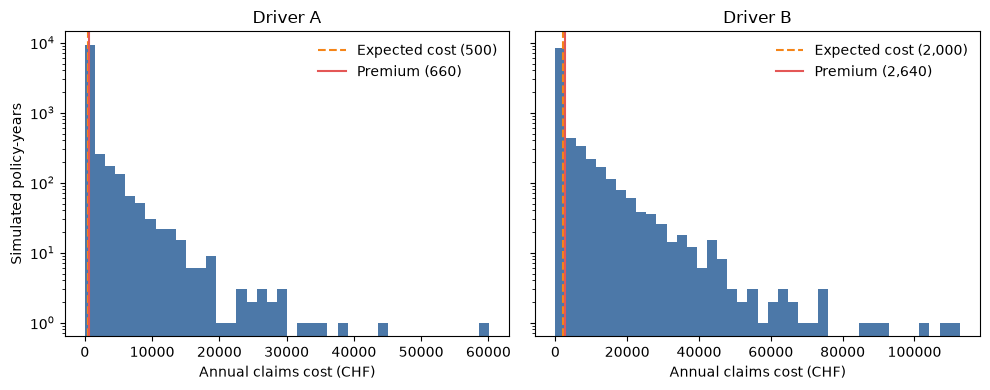

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, run in zip(axes, simulated, strict=True):
    quote = run.quote
    ax.hist(run.losses, bins=40, color="#4C78A8")
    ax.axvline(
        quote.expected_claims,
        color="#F58518",
        linestyle="--",
        linewidth=1.5,
        label=f"Expected cost ({quote.expected_claims:,.0f})",
    )
    ax.axvline(
        quote.premium,
        color="#E45756",
        linewidth=1.5,
        label=f"Premium ({quote.premium:,.0f})",
    )
    ax.set_yscale("log")
    ax.set_title(f"Driver {quote.driver.name}")
    ax.set_xlabel("Annual claims cost (CHF)")
    ax.legend(frameon=False)
axes[0].set_ylabel("Simulated policy-years")
fig.tight_layout()

chance = pd.DataFrame(
    [
        {
            "driver": run.quote.driver.name,
            "P(loss > premium)": float(np.mean(run.losses > run.quote.premium)),
            "P(loss > 1000)": float(np.mean(run.losses > 1000)),
        }
        for run in simulated
    ]
)
chance.round(4)

The tall bar at zero is the usual year: no claim. The premium sits just to the right of the expected cost, so it covers the average year plus the loadings. The long right-hand tail is the year in which claims exceed that price.

A price set a little above the average does not remove that chance. For driver A the expected cost is CHF 500. Charging CHF 1,000 still leaves the years in `P(loss > 1000)`, and those years cost more than was collected.